# Load Image


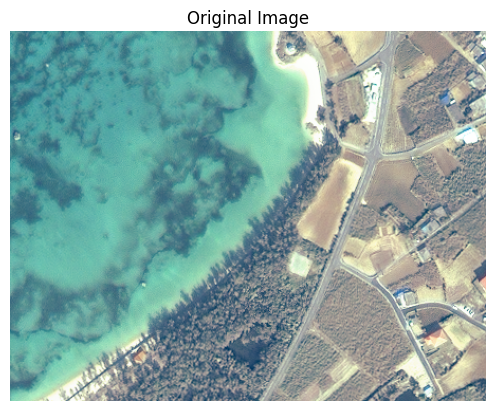

In [27]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.colors as colors

#load image
img = cv2.imread('irabu_zhang1.bmp')  
if img is None:
    raise FileNotFoundError("Could not read 'irabu_zhang1.bmp'. Check the filename/path and run from the correct folder.")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w, _ = img.shape

plt.imshow(img)
plt.title("Original Image")
plt.axis('off')
plt.show()

# Create a function

### kmean function

In [28]:
def init_centroid():
    # Random RGB values
    rgbs = np.array([
        [73.0, 150.5, 143.0],
        [123.0, 123.0, 123.0],
        [15.0, 151.0, 143.0],
        [14.0, 146.0, 143.0],
        [188.0, 166.0, 150.0]
    ]) / 255.0

    # Spatial midpoints (Normalized 0-1)
    # Defaulting to center or spread locations if not specified
    positions = np.array([
        [0.2, 0.2],
        [0.5, 0.5],
        [0.8, 0.2],
        [0.2, 0.8],
        [0.8, 0.8]
    ])

    return rgbs, positions

def kmean(X, k, max_iter=100, tol=1e-4):
    """Standard K-Means clustering algorithm."""
    n_samples, n_features = X.shape
    indices = np.random.choice(n_samples, k, replace=False)
    centroids = X[indices]
    for i in range(max_iter):
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)
        new_centroids = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j] for j in range(k)])
        if np.all(np.abs(new_centroids - centroids) < tol):
            break
        centroids = new_centroids
    return centroids, labels

def kmean_mahalanobis(X, k, max_iter=100, tol=1e-4, rho=1):
    """K-Means clustering using Mahalanobis distance."""
    n_samples, n_features = X.shape
    indices = np.random.choice(n_samples, k, replace=False)
    centroids = X[indices]
    A = [np.eye(n_features) for _ in range(k)]
    labels = np.zeros(n_samples, dtype=int)
    for iteration in range(max_iter):
        old_centroids = centroids.copy()
        distances = np.zeros((k, n_samples))
        for i in range(k):
            diff = X - centroids[i]
            distances[i] = np.sum(np.dot(diff, A[i]) * diff, axis=1)
        labels = np.argmin(distances, axis=0)
        for i in range(k):
            if np.any(labels == i):
                centroids[i] = X[labels == i].mean(axis=0)
                diff_cluster = X[labels == i] - centroids[i]
                S_i = np.dot(diff_cluster.T, diff_cluster) / len(diff_cluster)
                det_S = np.linalg.det(S_i)
                if det_S <= 0: det_S = 1e-10
                inv_S = np.linalg.inv(S_i + np.eye(n_features) * 1e-6)
                A[i] = (rho * det_S**(1.0/n_features)) * inv_S
        if np.all(np.abs(centroids - old_centroids) < tol):
            break
    return centroids, labels

def kmean_ninit(X, k, n_init=5, max_iter=100, tol=1e-4):
    """Wrapper to run K-Means multiple times and keep the best result."""
    best_centroids = None
    best_labels = None
    best_wcss = np.inf
    
    print(f"Running K-Means with n_init={n_init}...")
    for i in range(n_init):
        centroids, labels = kmean(X, k, max_iter, tol)
        # Calculate Within-Cluster Sum of Squares
        current_wcss = 0
        for j in range(k):
            if np.any(labels == j):
                current_wcss += np.sum((X[labels == j] - centroids[j])**2)
        
        if current_wcss < best_wcss:
            best_wcss = current_wcss
            best_centroids = centroids
            best_labels = labels
            
    return best_centroids, best_labels

def kmean_mahalanobis_ninit(X, k, n_init=5, max_iter=100, tol=1e-4, rho=1):
    """Wrapper to run Mahalanobis K-Means multiple times."""
    best_centroids = None
    best_labels = None
    best_obj = np.inf
    
    print(f"Running Mahalanobis K-Means with n_init={n_init}...")
    for i in range(n_init):
        centroids, labels = kmean_mahalanobis(X, k, max_iter, tol, rho)
        # Use simple WCSS or distance sum as objective for selection
        current_obj = 0
        for j in range(k):
            if np.any(labels == j):
                current_obj += np.sum((X[labels == j] - centroids[j])**2)
        
        if current_obj < best_obj:
            best_obj = current_obj
            best_centroids = centroids
            best_labels = labels
            
    return best_centroids, best_labels



### Fuzzy KMean function

In [29]:

def fuzzy_k_means_mahalanobis(X, k, b=2, max_iter=100, tol=1e-5, init_mu=None, rho=1):
    n, d = X.shape
    if init_mu is not None:
        mu = init_mu.copy()
    else:
        indices = np.random.choice(n, k, replace=False)
        mu = X[indices]
    A = [np.eye(d) for _ in range(k)]
    P = np.zeros((k, n))
    for iteration in range(max_iter):
        prev_mu = mu.copy()
        D = np.zeros((k, n))
        for i in range(k):
            diff = X - mu[i]
            D[i] = np.sum(np.dot(diff, A[i]) * diff, axis=1)
        D = np.fmax(D, np.finfo(np.float64).eps)
        inv_D = (1.0 / D) ** (1.0 / (b - 1))
        P = inv_D / np.sum(inv_D, axis=0)
        Pb = P**b
        for i in range(k):
            denominator = np.sum(Pb[i])
            mu[i] = np.sum(Pb[i][:, np.newaxis] * X, axis=0) / denominator
        for i in range(k):
            diff = X - mu[i]
            S_i = np.dot((Pb[i][:, np.newaxis] * diff).T, diff) / np.sum(Pb[i])
            det_S = np.linalg.det(S_i)
            if det_S <= 0: det_S = 1e-10
            inv_S = np.linalg.inv(S_i)
            A[i] = (rho * det_S**(1.0/d)) * inv_S
        if np.allclose(mu, prev_mu, atol=tol):
            break
    objective = np.sum(Pb * D)
    return mu, P, objective

def fuzzy_k_means(X, k, b=2, max_iter=100, tol=1e-5, n_init=5, init_mu=None):
    best_mu = None
    best_P = None
    best_obj = np.inf
    print(f"Running Mahalanobis-based Fuzzy K-Means (n_init={n_init})...")
    for i in range(n_init):
        current_init_mu = init_mu if (i == 0 and init_mu is not None) else None
        mu, P, obj = fuzzy_k_means_mahalanobis(X, k, b, max_iter, tol, init_mu=current_init_mu, rho=1)
        if obj < best_obj:
            best_obj = obj
            best_mu = mu
            best_P = P
    print(f"Best objective value found: {best_obj:.4f}")
    return best_mu, best_P


def fuzzy_k_means_euclidean_single(X, k, b=2, max_iter=100, tol=1e-5):
    """Standard Fuzzy K-Means using Euclidean Distance (Single Run)."""
    n_samples, n_features = X.shape
    # Initialize membership matrix P randomly
    P = np.random.rand(k, n_samples)
    P /= np.sum(P, axis=0)
    mu = np.zeros((k, n_features))

    for iteration in range(max_iter):
        prev_mu = mu.copy()
        Pb = P**b
        # Update Cluster Centers
        for i in range(k):
            mu[i] = np.sum(Pb[i][:, np.newaxis] * X, axis=0) / (np.sum(Pb[i]) + 1e-10)

        # Update Membership P based on Euclidean distance
        D = np.linalg.norm(X[:, np.newaxis] - mu, axis=2).T
        D = np.fmax(D, np.finfo(np.float64).eps)

        inv_D = (1.0 / D) ** (2.0 / (b - 1))
        P = inv_D / np.sum(inv_D, axis=0)

        if np.allclose(mu, prev_mu, atol=tol):
            break

    # Calculate objective function: sum of squared errors weighted by membership
    objective = np.sum(Pb * (D**2))
    return mu, P, objective

def fuzzy_k_means_ninit(X, k, b=2, max_iter=100, tol=1e-5, n_init=5):
    """Wrapper to run Euclidean Fuzzy multiple times and keep the best result."""
    best_mu, best_P, best_obj = None, None, np.inf
    print(f"Running Standard Euclidean Fuzzy (n_init={n_init})...")
    
    for i in range(n_init):
        mu, P, obj = fuzzy_k_means_euclidean_single(X, k, b, max_iter, tol)
        if obj < best_obj:
            best_obj = obj
            best_mu = mu
            best_P = P
    
    print(f"Best Euclidean Fuzzy objective: {best_obj:.4f}")
    return best_mu, best_P

def fuzzy_k_means_standard(X, k, b=2, max_iter=100, tol=1e-5):
    """Standard Fuzzy K-Means using Euclidean Distance."""
    n_samples, n_features = X.shape
    P = np.random.rand(k, n_samples)
    P /= np.sum(P, axis=0)
    mu = np.zeros((k, n_features))
    for iteration in range(max_iter):
        prev_mu = mu.copy()
        Pb = P**b
        for i in range(k):
            mu[i] = np.sum(Pb[i][:, np.newaxis] * X, axis=0) / np.sum(Pb[i])
        D = np.linalg.norm(X[:, np.newaxis] - mu, axis=2).T
        D = np.fmax(D, np.finfo(np.float64).eps)
        inv_D = (1.0 / D) ** (2.0 / (b - 1))
        P = inv_D / np.sum(inv_D, axis=0)
        if np.allclose(mu, prev_mu, atol=tol):
            print(f"Standard Fuzzy converged at iteration {iteration}")
            break
    return mu, P


def reconstruct_image(memberships, k, h, w, original_raw_pixels):
    labels = np.argmax(memberships, axis=0)
    new_colors = np.zeros((k, 3))
    for i in range(k):
        if np.any(labels == i):
            new_colors[i] = np.mean(original_raw_pixels[labels == i], axis=0)
    return new_colors[labels].reshape(h, w, 3).astype(np.uint8)

def get_segmented_img(memberships, k, raw_pixels, h, w):
    labels = np.argmax(memberships, axis=0)
    centroids = np.zeros((k, 3))
    for i in range(k):
        if np.any(labels == i):
            centroids[i] = np.mean(raw_pixels[labels == i], axis=0)
    return (centroids[labels] * 255).astype(np.uint8).reshape(h, w, 3)

# Function call 

In [30]:
img_np = np.array(img)
h, w, c = img_np.shape

### kmean

In [31]:
#kmean
k_val = 5

# 1. RGB K-Means 
X_rgb_only = img_np.reshape(-1, 3).astype(float) / 255.0
print("Running K-Means (RGB)...")
rgb_centroids, rgb_labels = kmean(X_rgb_only, k=k_val)

# 2. HSV K-Means 
X_hsv_only = colors.rgb_to_hsv(img_np / 255.0).reshape(-1, 3)
print("Running K-Means (HSV)...")
hsv_centroids, hsv_labels = kmean(X_hsv_only, k=k_val)

#kmean mahalanobis
#3. RGB K-Means with Mahalanobis Distance
X_rgb_maha = img_np.reshape(-1, 3).astype(float) / 255.0
print("Running K-Means (RGB Mahalanobis)...")
rgb_centroids_m, rgb_labels_m = kmean_mahalanobis(X_rgb_only, k=k_val)

# 4. HSV K-Means with Mahalanobis Distance 
X_hsv_only = colors.rgb_to_hsv(img_np / 255.0).reshape(-1, 3)
print("Running K-Means (HSV Mahalanobis)...")
hsv_centroids_m, hsv_labels_m = kmean_mahalanobis(X_hsv_only, k=k_val)


Running K-Means (RGB)...
Running K-Means (HSV)...
Running K-Means (RGB Mahalanobis)...
Running K-Means (HSV Mahalanobis)...


In [32]:
#update with n_init
n_init_val = 5

# 1. RGB K-Means (n_init)
print("Processing RGB K-Means...")
rgb_centroids_ninit, rgb_labels_ninit = kmean_ninit(X_rgb_only, k=k_val, n_init=n_init_val)

# 2. HSV K-Means (n_init)
print("Processing HSV K-Means...")
hsv_centroids_ninit, hsv_labels_ninit = kmean_ninit(X_hsv_only, k=k_val, n_init=n_init_val)

# 3. RGB K-Means Mahalanobis (n_init)
print("Processing RGB Mahalanobis K-Means...")
rgb_centroids_m_ninit, rgb_labels_m_ninit = kmean_mahalanobis_ninit(X_rgb_only, k=k_val, n_init=n_init_val)

# 4. HSV K-Means Mahalanobis (n_init)
print("Processing HSV Mahalanobis K-Means...")
hsv_centroids_m_ninit, hsv_labels_m_ninit = kmean_mahalanobis_ninit(X_hsv_only, k=k_val, n_init=n_init_val)

Processing RGB K-Means...
Running K-Means with n_init=5...
Processing HSV K-Means...
Running K-Means with n_init=5...
Processing RGB Mahalanobis K-Means...
Running Mahalanobis K-Means with n_init=5...
Processing HSV Mahalanobis K-Means...
Running Mahalanobis K-Means with n_init=5...


### fuzzy kmean

##### fuzzy kmean


In [33]:

h, w, c = img_np.shape
k_val = 5

# 1. Prepare Features (Color Only)
X_rgb_std = img_np.reshape(-1, 3).astype(float) / 255.0
X_hsv_std = colors.rgb_to_hsv(img_np / 255.0).reshape(-1, 3)

# 2. Run Standard Fuzzy K-Means (Euclidean)
print("Running Standard (RGB)...")
mu_rgb_std, p_rgb_std = fuzzy_k_means_standard(X_rgb_std, k=k_val)

print("Running Standard (HSV)...")
mu_hsv_std, p_hsv_std = fuzzy_k_means_standard(X_hsv_std, k=k_val)



   

Running Standard (RGB)...
Standard Fuzzy converged at iteration 57
Running Standard (HSV)...
Standard Fuzzy converged at iteration 24


In [34]:
X_rgb_only = img_np.reshape(-1, 3).astype(float) / 255.0
X_hsv_only = colors.rgb_to_hsv(img_np / 255.0).reshape(-1, 3)

print("Running Mahalanobis-based Fuzzy (RGB Only, n_init=5)...")
mu_maha_rgb_only, p_maha_rgb_only = fuzzy_k_means(X_rgb_only, k=k_val, b=1.5, n_init=5)

print("Running Mahalanobis-based Fuzzy (HSV Only, n_init=5)...")
mu_maha_hsv_only, p_maha_hsv_only = fuzzy_k_means(X_hsv_only, k=k_val, b=1.5, n_init=5)


Running Mahalanobis-based Fuzzy (RGB Only, n_init=5)...
Running Mahalanobis-based Fuzzy K-Means (n_init=5)...
Best objective value found: 431.1556
Running Mahalanobis-based Fuzzy (HSV Only, n_init=5)...
Running Mahalanobis-based Fuzzy K-Means (n_init=5)...
Best objective value found: 927.3437


##### fuzzy kmean with spital and mahalanobis

In [35]:

spatial_weight = 0.5 # Spatial weight

print(f"Processing with k={k_val}, spatial_weight={spatial_weight} on {h}x{w} image...")

# Prepare Spatial Coordinates
yy, xx = np.mgrid[0:h, 0:w]
X_spatial = np.c_[xx.ravel() / w, yy.ravel() / h] # Spatial features (0-1 normalized)

# Initialize centroids (for HSV and RGB) 
init_rgbs, init_pos = init_centroid()

# Prepare data for Mahalanobis-based Fuzzy K-Means (HSV + Spatial)
# Generates `img_memberships` needed for the final visualization
img_hsv = colors.rgb_to_hsv(img_np / 255.0)
X_color_hsv = img_hsv.reshape(-1, 3)
X_combined = np.hstack([X_color_hsv, X_spatial * spatial_weight])

# Convert initial RGB centroids to HSV and combine with spatial for initialization
init_hsvs = colors.rgb_to_hsv(init_rgbs.reshape(1, -1, 3)).reshape(-1, 3)
init_mu = np.hstack([init_hsvs, init_pos * spatial_weight])

print("Running Mahalanobis-based Fuzzy K-Means (HSV + Spatial) for final result...")
# Note: n_init=100 for better convergence, b=1.5 as used previously
img_centroids, img_memberships = fuzzy_k_means(X_combined, k=k_val, b=1.5, max_iter=100, tol=1e-4, n_init=100, init_mu=init_mu)

# Raw RGB pixels (normalized 0-1) for reconstruction in the final cell
raw_rgb_pixels = img_np.reshape(-1, 3).astype(float) / 255.0

Processing with k=5, spatial_weight=0.5 on 350x450 image...
Running Mahalanobis-based Fuzzy K-Means (HSV + Spatial) for final result...
Running Mahalanobis-based Fuzzy K-Means (n_init=100)...
Best objective value found: 2760.0906


In [36]:
X_vals = img_np.reshape(-1, 3).astype(float) / 255.0
k_val = 5

# 2. Run Euclidean Fuzzy with n_init=5
best_mu_euc, best_p_euc = fuzzy_k_means_ninit(X_vals, k=k_val, n_init=5)



Running Standard Euclidean Fuzzy (n_init=5)...
Best Euclidean Fuzzy objective: 992.6696


# Plot the result

### kmean

In [37]:
def reconstruct(labels, k, raw_pixels):
    out_colors = np.zeros((k, 3))
    for i in range(k):
        if np.any(labels == i):
            out_colors[i] = np.mean(raw_pixels[labels == i], axis=0)
    return out_colors[labels].reshape(h, w, 3).astype(np.uint8)

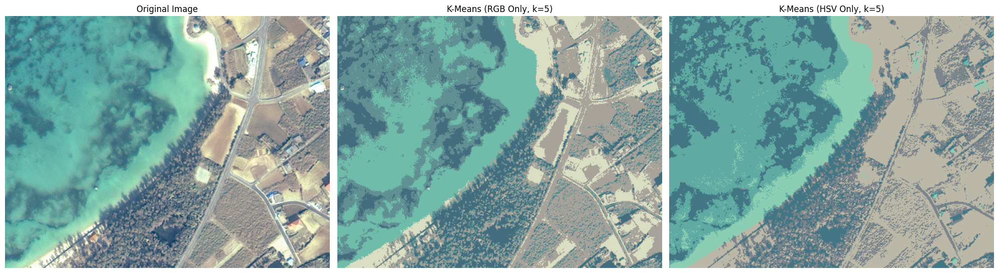

In [38]:
# kmean
# Reconstruct using original RGB pixel values
raw_rgb = img_np.reshape(-1, 3)
seg_rgb = reconstruct(rgb_labels, k_val, raw_rgb)
seg_hsv = reconstruct(hsv_labels, k_val, raw_rgb)

# Visualization
plt.figure(figsize=(20, 7))
plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(seg_rgb)
plt.title(f"K-Means (RGB Only, k={k_val})")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(seg_hsv)
plt.title(f"K-Means (HSV Only, k={k_val})")
plt.axis('off')

plt.tight_layout()
plt.show()


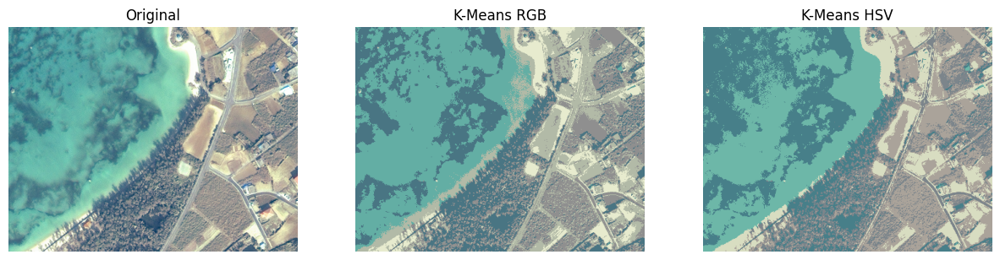

In [39]:
#with n
raw_rgb = img_np.reshape(-1, 3)

# Reconstruct images from K-Means (Kmean n_init)
seg_rgb_n = reconstruct(rgb_labels_ninit, k_val, raw_rgb)
seg_hsv_n = reconstruct(hsv_labels_ninit, k_val, raw_rgb)


# Plot Kmean results
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(seg_rgb_n)
plt.title(f"K-Means RGB")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(seg_hsv_n)
plt.title(f"K-Means HSV")
plt.axis('off')
plt.show()


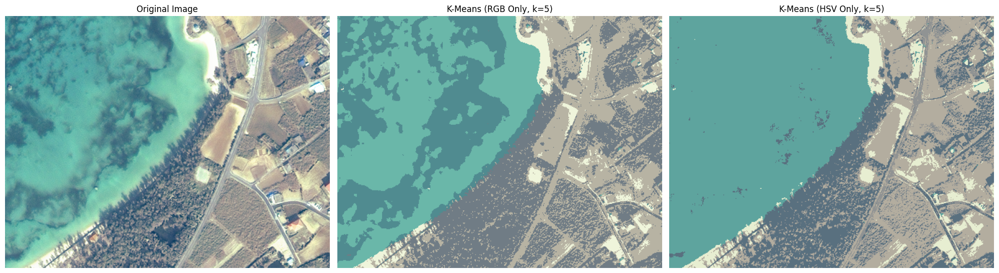

In [40]:

# kmean mahalanobis
# Reconstruct using original RGB pixel values
raw_rgb = img_np.reshape(-1, 3)
seg_rgb_m = reconstruct(rgb_labels_m_ninit, k_val, raw_rgb)
seg_hsv_m = reconstruct(hsv_labels_m_ninit, k_val, raw_rgb)

# Visualization
plt.figure(figsize=(20, 7))
plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(seg_rgb_m)
plt.title(f"K-Means (RGB Only, k={k_val})")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(seg_hsv_m)
plt.title(f"K-Means (HSV Only, k={k_val})")
plt.axis('off')

plt.tight_layout()
plt.show()


### Fuzzy Kmean

##### Fuzzy Kmean

In [41]:
def reconstruct_fuzzy(memberships, k, original_raw):
    labels = np.argmax(memberships, axis=0)
    out_colors = np.zeros((k, 3))
    for i in range(k):
        if np.any(labels == i):
            out_colors[i] = np.mean(original_raw[labels == i], axis=0)
    return out_colors[labels].reshape(h, w, 3).astype(np.uint8)


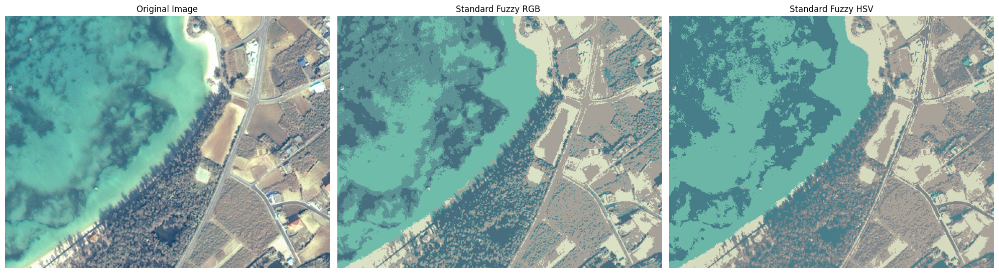

In [42]:
raw_rgb = img_np.reshape(-1, 3)
seg_fuzzy_rgb = reconstruct_fuzzy(p_rgb_std, k_val, raw_rgb)
seg_fuzzy_hsv = reconstruct_fuzzy(p_hsv_std, k_val, raw_rgb)

# 4. Visualization
plt.figure(figsize=(20, 7))
plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(seg_fuzzy_rgb)
plt.title(f"Standard Fuzzy RGB ")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(seg_fuzzy_hsv)
plt.title(f"Standard Fuzzy HSV")
plt.axis('off')

plt.tight_layout()
plt.show()

##### fuzzy kmean n_init

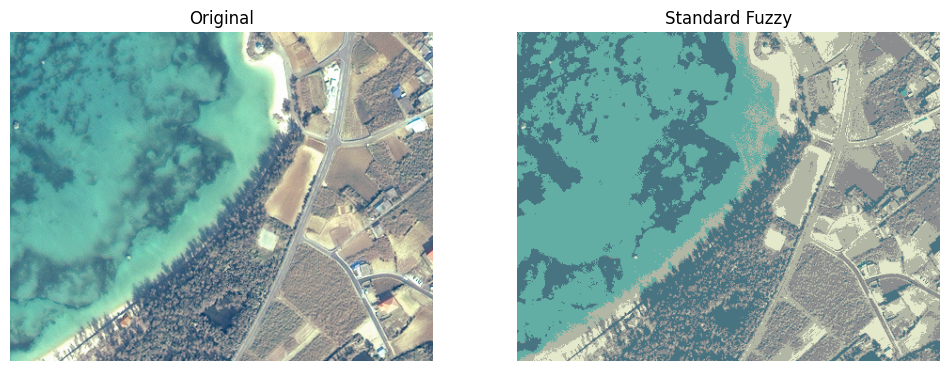

In [43]:
labels_euc = np.argmax(best_p_euc, axis=0)
raw_pixels = img_np.reshape(-1, 3)
seg_colors = np.zeros((k_val, 3))
for i in range(k_val):
    if np.any(labels_euc == i):
        seg_colors[i] = np.mean(raw_pixels[labels_euc == i], axis=0)

seg_img_euc = seg_colors[labels_euc].reshape(h, w, 3).astype(np.uint8)

# 4. Display results
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img_np)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(seg_img_euc)
plt.title(f"Standard Fuzzy")
plt.axis('off')
plt.show()

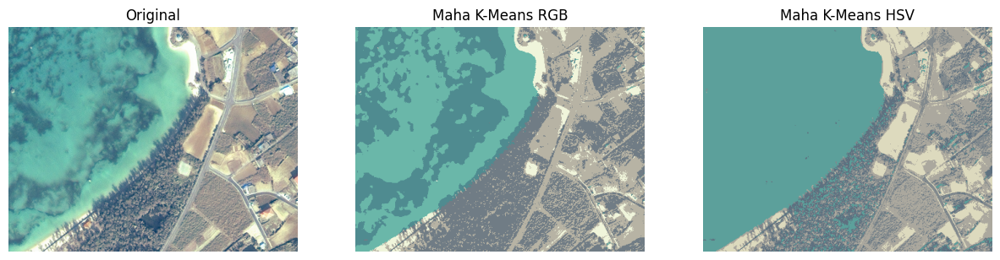

In [44]:
#with loop and mahalanobis

seg_rgb_m_n = reconstruct(rgb_labels_m, k_val, raw_rgb)
seg_hsv_m_n = reconstruct(hsv_labels_m, k_val, raw_rgb)


# Plot Mahalanobis results
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(seg_rgb_m_n)
plt.title(f"Maha K-Means RGB")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(seg_hsv_m_n)
plt.title(f"Maha K-Means HSV")
plt.axis('off')
plt.show()

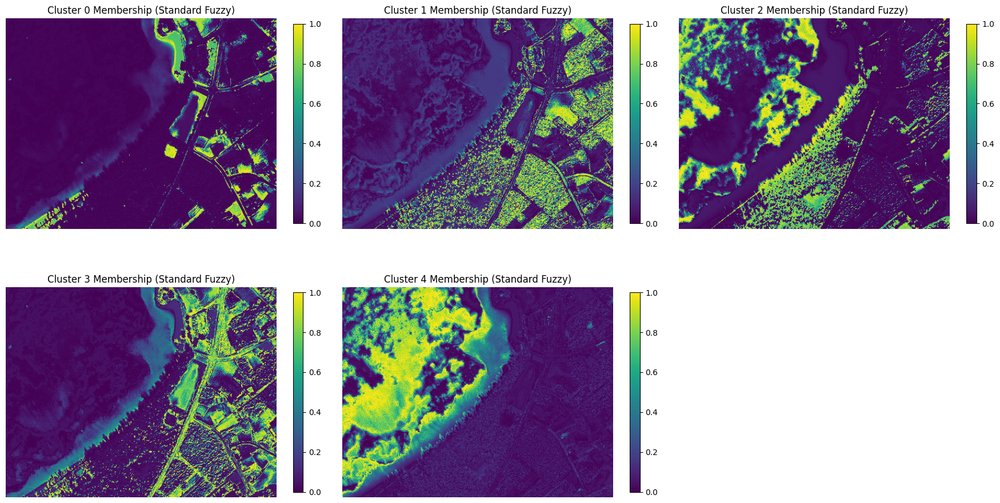

In [45]:
# Create membership map visualization for N-INIT Fuzzy K-Means (Euclidean) result
membership_maps_euc = best_p_euc.reshape(k_val, h, w)
label_map_euc = np.argmax(best_p_euc, axis=0).reshape(h, w)

plt.figure(figsize=(18, 10))

for i in range(k_val):
    plt.subplot(2, 3, i + 1)
    plt.imshow(membership_maps_euc[i], cmap='viridis', vmin=0, vmax=1)
    plt.title(f"Cluster {i} Membership (Standard Fuzzy)")
    plt.axis('off')
    plt.colorbar(shrink=0.7)


plt.tight_layout()
plt.show()

##### Fuzzy + Mahalanobis

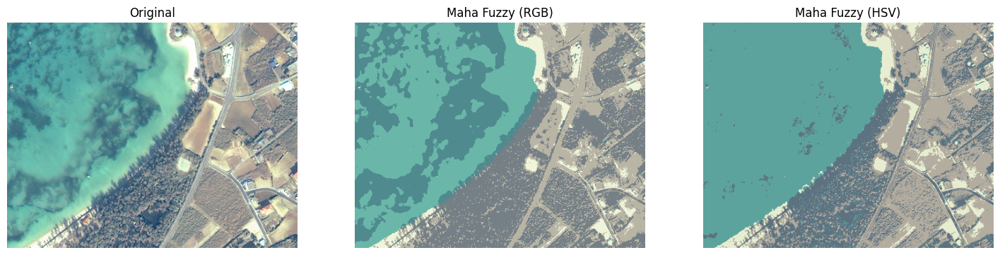

In [46]:


# 2. Reconstruct
seg_maha_rgb = reconstruct_fuzzy(p_maha_rgb_only, k_val, img_np.reshape(-1, 3))
seg_maha_hsv = reconstruct_fuzzy(p_maha_hsv_only, k_val, img_np.reshape(-1, 3))

# 3. Visualize
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(img_np)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(seg_maha_rgb)
plt.title("Maha Fuzzy (RGB)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(seg_maha_hsv)
plt.title("Maha Fuzzy (HSV)")
plt.axis('off')
plt.show()

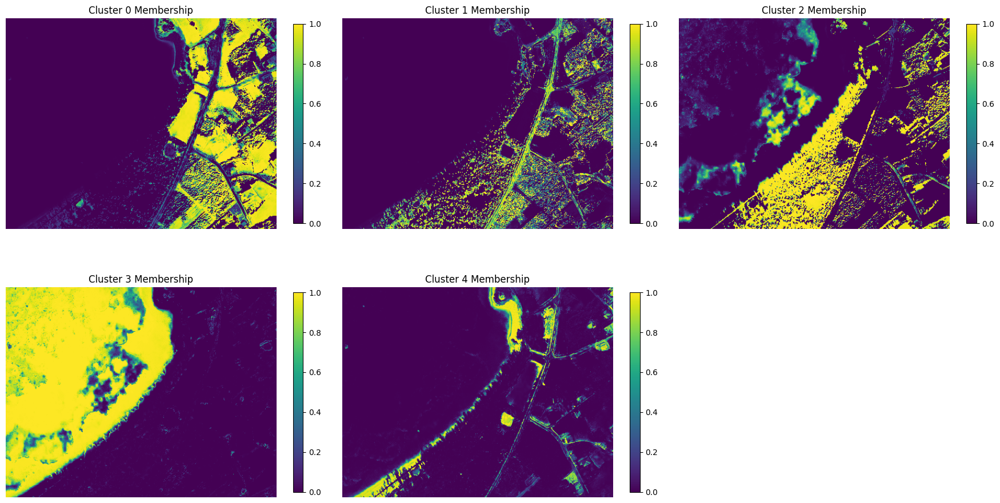

In [47]:
membership_maps = img_memberships.reshape(k_val, h, w)
label_map = np.argmax(img_memberships, axis=0).reshape(h, w)

plt.figure(figsize=(18, 10))

for i in range(k_val):
    plt.subplot(2, 3, i + 1)
    plt.imshow(membership_maps[i], cmap='viridis', vmin=0, vmax=1)
    plt.title(f"Cluster {i} Membership")
    plt.axis('off')
    plt.colorbar(shrink=0.7)

# plt.subplot(2, 3, 6)
# plt.imshow(label_map, cmap='tab20')
# plt.title("Maximum Membership Label Map")
# plt.axis('off')
# plt.colorbar(shrink=0.7)

plt.tight_layout()
plt.show()

##### Fuzzy Kmean with n_init and mahalanobis with spatial


Generating RGB-based Fuzzy+Mahalanobis for comparison...
Running Mahalanobis-based Fuzzy K-Means (n_init=10)...
Best objective value found: 1678.2512


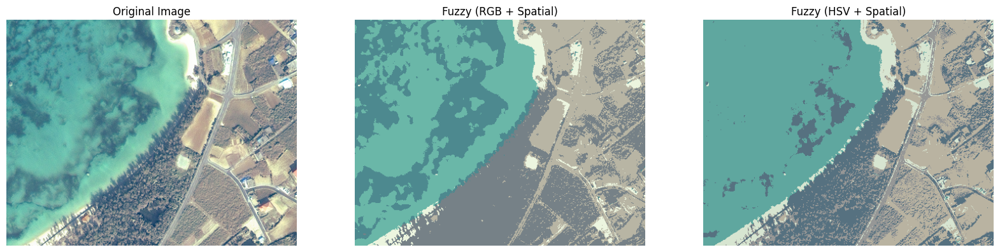

In [48]:
# For both RGB and HSV features and Visualize
X_rgb_feat = img_np.reshape(-1, 3).astype(float) / 255.0
X_combined_rgb = np.hstack([X_rgb_feat, X_spatial * spatial_weight])
init_mu_rgb = np.hstack([init_rgbs, init_pos * spatial_weight])

print("Generating RGB-based Fuzzy+Mahalanobis for comparison...")
_, memberships_rgb = fuzzy_k_means(X_combined_rgb, k=k_val, b=1.5, max_iter=100, tol=1e-2, n_init=10, init_mu=init_mu_rgb)

seg_img_fcm_rgb = get_segmented_img(memberships_rgb, k_val, raw_rgb_pixels, h, w)
seg_img_fcm_hsv = get_segmented_img(img_memberships, k_val, raw_rgb_pixels, h, w)

# 6. Display results: Original, RGB-fuzzy, HSV-fuzzy
plt.figure(figsize=(20, 7))
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(seg_img_fcm_rgb)
plt.title("Fuzzy (RGB + Spatial)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(seg_img_fcm_hsv)
plt.title("Fuzzy (HSV + Spatial)")
plt.axis('off')

plt.show()

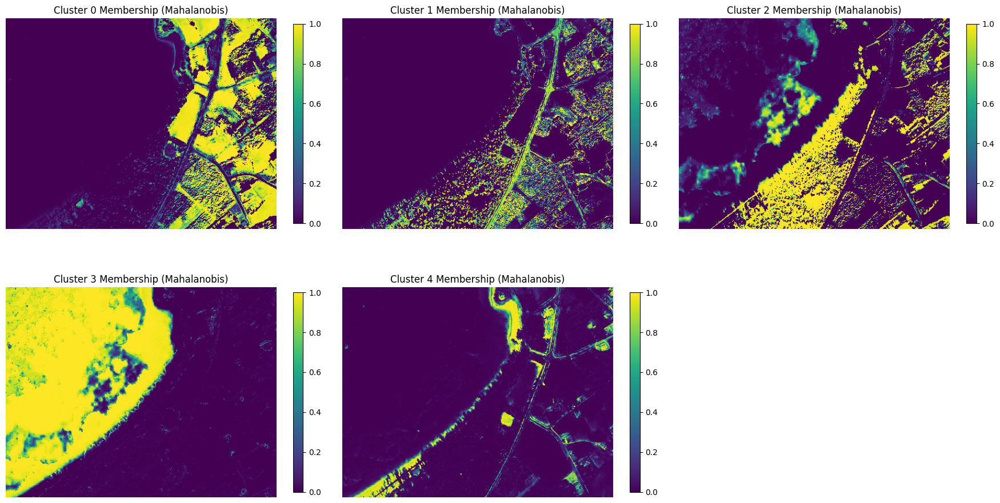

In [49]:
# Create membership map visualization for Fuzzy K-Means Mahalanobis result
membership_maps_mahal = img_memberships.reshape(k_val, h, w)
label_map_mahal = np.argmax(img_memberships, axis=0).reshape(h, w)

plt.figure(figsize=(18, 10))

for i in range(k_val):
    plt.subplot(2, 3, i + 1)
    plt.imshow(membership_maps_mahal[i], cmap='viridis', vmin=0, vmax=1)
    plt.title(f"Cluster {i} Membership (Mahalanobis)")
    plt.axis('off')
    plt.colorbar(shrink=0.7)

# plt.subplot(2, 3, 6)
# plt.imshow(label_map_mahal, cmap='tab20')
# plt.title("Maximum Membership Label Map (Mahalanobis)")
# plt.axis('off')
# plt.colorbar(shrink=0.7)

plt.tight_layout()
plt.show()